# Batch NARDINI+ with `sparrow.nardini`

The companion notebook (`nardini_from_protein_objects.ipynb`) covers single sequences via
`Protein.nardini`. This one covers the module API, which is what you want when you have
**many** sequences, or when you want to **build your own compositional background** rather
than use one of the bundled ones.

The workflow is two steps:

1. **A compositional background** — the reference set the 54 compositional features are
   z-scored against. Either build one from your own IDRs with `build_background()`, or load
   one of nine published IDRomes with `load_reference_background()`.
2. **The vectors** — `nardini_vectors()` scores every sequence, returning patterning
   z-scores (against each sequence's own scrambles) and compositional z-scores (against the
   background).

Optionally a third step: `result.gin_clusters()` assigns each sequence to one of the 30
published human GIN grammars.

In [1]:
import random
import tempfile
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

from sparrow import Protein
from sparrow.nardini import (
    REFERENCE_SPECIES,
    NardiniBackground,
    build_background,
    gin_cluster_definitions,
    load_gin_reference,
    load_reference_background,
    nardini_vectors,
)

%matplotlib inline

## Step 1a: building your own background

`build_background()` accepts a FASTA path, a dict of `{name: sequence}`, a list of
sequences, or a list of `Protein` objects. It computes the mean and standard deviation of
each of the 54 compositional features across the set — that is all a background is.

> **Note on this example.** The sequences below are *synthetic*, drawn from an IDR-like
> amino-acid distribution, purely so this notebook is self-contained and reproducible. A
> background is only as good as the set behind it: in real use, point this at a FASTA of
> the IDRs you actually want to compare against — your organism's IDRome, a family of
> interest, a set of designed constructs.

In [2]:
rng = random.Random(1234)

# a crude IDR-like composition: enriched in S/T/G/Q/N/P/E/D/K/R, depleted in hydrophobics
IDR_ALPHABET = "SSSTTTGGGQQQNNNPPPEEEDDDKKKRRRAAALLLVVVMIYFWHC"

my_idrs = {
    f"idr_{i:03d}": "".join(
        rng.choice(IDR_ALPHABET) for _ in range(rng.randint(100, 400))
    )
    for i in range(400)
}

background = build_background(my_idrs)
background

NardiniBackground|54 features|n=400

In [3]:
print("features         :", len(background.feature_names))
print("sequences used   :", background.num_sequences)
print("metadata         :", background.metadata)
print()
print(f"{'feature':18s} {'mean':>9s} {'std':>9s}")
for name in ["FCR", "NCPR", "Frac S", "Frac P", "Hydrophobicity"]:
    index = background.feature_names.index(name)
    print(f"{name:18s} {background.mean[index]:9.4f} {background.std[index]:9.4f}")

features         : 54
sequences used   : 400
metadata         : {'num_sequences_used': 400, 'num_sequences_skipped': 0, 'min_length': 1, 'num_degenerate_features': 3}

feature                 mean       std
FCR                   0.2586    0.0300
NCPR                 -0.0021    0.0366
Frac S                0.0648    0.0177
Frac P                0.0666    0.0181
Hydrophobicity        3.5989    0.2037


Backgrounds are worth saving — building one over a real IDRome takes a while, and you want
the *same* background across everything you compare.

In [4]:
with tempfile.TemporaryDirectory() as directory:
    path = Path(directory) / "my_background.npz"
    background.save(path)
    reloaded = NardiniBackground.load(path)

    print("saved and reloaded :", reloaded)
    print("identical means    :", np.array_equal(background.mean, reloaded.mean))

saved and reloaded : NardiniBackground|54 features|n=400
identical means    : True


`build_background` also takes `min_length` (skip anything shorter — the published
backgrounds use IDRs of 30+ residues) and `show_progress=True` for a progress bar, which
you will want when reading a whole proteome.

In [5]:
filtered = build_background(my_idrs, min_length=200)
print(f"min_length=1   : {background.num_sequences} sequences used")
print(f"min_length=200 : {filtered.num_sequences} sequences used, "
      f"{filtered.metadata['num_sequences_skipped']} skipped")

min_length=1   : 400 sequences used
min_length=200 : 271 sequences used, 129 skipped


### sparrow tells you when a background is too weak

A background is only as good as the set behind it, and the failure is quiet: a
feature that never varies across your reference set has no scale to divide by, so its
z-score comes back as exactly `0.0` for every sequence you ever score. That reads as
"perfectly average" when it actually means "unmeasurable".

`build_background()` warns when either problem is present — too few sequences for the
means and standard deviations to be determined, or too many constant features. The
thresholds are calibrated against the published IDRomes, which have 0 or 1 constant
features out of 54.

In [6]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    too_small = build_background({name: my_idrs[name] for name in list(my_idrs)[:3]})

print(caught[0].category.__name__)
print()
print(caught[0].message)

BackgroundQualityWarning

This NARDINI+ compositional background is unlikely to give meaningful z-scores: it was built from only 3 sequences (recommended: at least 50), so every per-feature mean and standard deviation is poorly determined; and 16 of 54 features are constant across the set (C Patch, D Patch, E Patch, F Patch, H Patch, ...), so their z-scores will be reported as exactly 0.0 for every sequence you score - not because those sequences are average, but because the background cannot measure them. Consider using more reference sequences, or one of the published IDRome backgrounds via load_reference_background(). The patterning half of a NARDINI+ vector does not use a background at all and is unaffected.


And it is telling the truth — every compositional z-score against that background is
zero:

In [7]:
probe = "MGSQNSTPGQNSTPGKQNSTEPGQNSTPGDQNSTPGKQNSTPGEQNSTPGRQN"

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    weak = nardini_vectors({"probe": probe}, background=too_small,
                           num_scrambles=200, seed=1)
    good = nardini_vectors({"probe": probe}, background=background,
                           num_scrambles=200, seed=1)

print("against the 3-sequence background :",
      np.count_nonzero(weak.composition_zscores), "of 54 z-scores are non-zero")
print("against the 400-sequence background:",
      np.count_nonzero(good.composition_zscores), "of 54 z-scores are non-zero")

against the 3-sequence background : 38 of 54 z-scores are non-zero
against the 400-sequence background: 51 of 54 z-scores are non-zero


Silence it with `warnings.filterwarnings("ignore", category=SparrowWarning)` if you know
your set is small and you only care about the patterning half — which never uses a
background at all.

## Step 1b: the bundled published backgrounds

Nine IDRomes ship with sparrow, taken from the GIN resource. `'human'` is the one the GIN
cluster centroids were defined in, so it is the right choice if you intend to assign
clusters.

In [8]:
for key, name in REFERENCE_SPECIES.items():
    print(f"  {key:12s} {name}")

human = load_reference_background("human")
print()
print(human)
print()
for key, value in human.metadata.items():
    print(f"  {key:22s} {str(value)[:88]}")

  human        Homo sapiens
  mouse        Mus musculus
  rat          Rattus norvegicus
  xenopus      Xenopus tropicalis
  fly          Drosophila melanogaster
  zebrafish    Danio rerio
  yeast        Saccharomyces cerevisiae
  worm         Caenorhabditis elegans
  arabidopsis  Arabidopsis thaliana

NardiniBackground|54 features|n=?

  species                Homo sapiens
  species_key            human
  source                 https://docs.google.com/spreadsheets/d/1yxt0R1G0gdI2bGpjYXgk_h7-1qA6EY6J/gviz/tq?tqx=out
  source_repository      https://github.com/kierstenruff/RUFF_KING_Grammars_of_IDRs_using_NARDINI-
  citation               Ruff, K. M., King, M. R., Ying, A. W., Liu, V., Pant, A., Lieberman, W. E., Shinn, M. K.
  licence                MIT
  description            Published NARDINI+ compositional background for the Homo sapiens IDRome (IDRs >= 30 resi
  num_sequences_known    False


## Step 2: NARDINI+ vectors for a set of sequences

For a realistic set, we take the IDRs of a real protein — human BARD1 — and add three
designed sequences with grammars we can predict in advance, as a sanity check on the
output.

In [9]:
BARD1_sequence = (
    "MPDNRQPRNRQPRIRSGNEPRSAPAMEPDGRGAWAHSRAALDRLEKLLRCSRCTNILREPVCLGGCEHIFCSNCVSDCIGT"
    "GCPVCYTPAWIQDLKINRQLDSMIQLCSKLRNLLHDNELSDLKEDKPRKSLFNDAGNKKNSIKMWFSPRSKKVRYVVSKAS"
    "VQTQPAIKKDASAQQDSYEFVSPSPPADVSERAKKASARSGKKQKKKTLAEINQKWNLEAEKEDGEFDSKEESKQKLVSFC"
    "SQPSVISSPQINGEIDLLASGSLTESECFGSLTEVSLPLAEQIESPDTKSRNEVVTPEKVCKNYLTSKKSLPLENNGKRGH"
    "HNRLSSPISKRCRTSILSTSGDFVKQTVPSENIPLPECSSPPSCKRKVGGTSGRKNSNMSDEFISLSPGTPPSTLSSSSYR"
    "RVMSSPSAMKLLPNMAVKRNHRGETLLHIASIKGDIPSVEYLLQNGSDPNVKDHAGWTPLHEACNHGHLKVVELLLQHKAL"
    "VNTTGYQNDSPLHDAAKNGHVDIVKLLLSYGASRNAVNIFGLRPVDYTDDESMKSLLLLPEKNESSSASHCSVMNTGQRRD"
    "GPLVLIGSGLSSEQQKMLSELAVILKAKKYTEFDSTVTHVVVPGDAVQSTLKCMLGILNGCWILKFEWVKACLRRKVCEQE"
    "EKYEIPEGPRRSRLNREQLLPKLFDGCYFYLWGTFKHHPKDNLIKLVTAGGGQILSRKPKPDSDVTQTINTVAYHARPDSD"
    "QRFCTQYIIYEDLCNYHPERVRQGKVWKAPSSWFIDCVMSFELLPLDS"
)

sequences = {}

# the real IDRs of BARD1, keeping only those long enough to be worth scoring
for start, end in Protein(BARD1_sequence).predictor.disorder_domains(return_boundaries=True):
    if end - start >= 30:
        sequences[f"BARD1_{start}_{end}"] = BARD1_sequence[start:end]

# designed sequences with grammars we can predict
sequences["designed_DE_tract"] = "MGSDEDEDEDEDEDEDEDEGSSGSSGSSDEDEDEDEDEDEGSSGSSKKAAPQQ"
sequences["designed_polyQ"] = "MGSQQQQQQQQQQQQQQQQQQQQQQQQGSSGSSPPQQQQQQQQQQQQQQKKAA"
sequences["designed_mixed"] = "MGSQNSTPGQNSTPGKQNSTEPGQNSTPGDQNSTPGKQNSTPGEQNSTPGRQN"

for name, sequence in sequences.items():
    print(f"  {name:22s} {len(sequence):4d} residues")

  BARD1_0_38               38 residues
  BARD1_117_419           302 residues
  designed_DE_tract        53 residues
  designed_polyQ           53 residues
  designed_mixed           53 residues


In [10]:
result = nardini_vectors(sequences, background=human, num_scrambles=10000, seed=42)
result

NardiniResult|5 sequences|90 features

### What is on a `NardiniResult`

The two halves are available separately or concatenated, always in the same order:
36 patterning features then 54 compositional ones.

In [11]:
print("names               :", result.names)
print("patterning block    :", result.patterning_zscores.shape)
print("composition block   :", result.composition_zscores.shape)
print("full matrix         :", result.zscores.shape)
print("feature names       :", len(result.feature_names))
print("has_composition     :", result.has_composition)
print("backend             :", result.backend)
print()
print("raw (un-z-scored) values are kept too:")
print("  raw_patterning    :", result.raw_patterning.shape)
print("  raw_composition   :", result.raw_composition.shape)

names               : ('BARD1_0_38', 'BARD1_117_419', 'designed_DE_tract', 'designed_polyQ', 'designed_mixed')
patterning block    : (5, 36)
composition block   : (5, 54)
full matrix         : (5, 90)
feature names       : 90
has_composition     : True
backend             : nardini

raw (un-z-scored) values are kept too:
  raw_patterning    : (5, 36)
  raw_composition   : (5, 54)


`result.backend` is recorded because the numbers are **not comparable across backends**.
If you are storing vectors, store the backend alongside them.

### Working with the numbers

`result.zscores` is a plain `(n_sequences, 90)` array, and for a lot of downstream work
(clustering, dimensionality reduction, feeding a model) that is all you need. When you want
the labels attached, `to_table()` gives you a `FeatureTable`.

In [12]:
table = result.to_table()

print(table)
print()
print("one feature across all sequences:")
print("  ", np.round(table["pos-neg"], 2))
print()
print("one sequence as a labelled vector:")
row = table.row("designed_polyQ")
print("  ", row, "->", "Q Patch =", round(row["Q Patch"], 2))
print()
print("a single value, two equivalent ways:")
print("  ", round(table["designed_polyQ", "Frac Q"], 3),
      "==", round(table.row("designed_polyQ")["Frac Q"], 3))
print()
print("the underlying array is always there:")
print("  ", type(table.values), table.values.shape)

FeatureTable|5 rows x 90 columns

one feature across all sequences:
   [0.3  2.94 0.   0.   0.  ]

one sequence as a labelled vector:
   FeatureVector 'designed_polyQ'|90 features -> Q Patch = 19.36

a single value, two equivalent ways:
   14.672 == 14.672

the underlying array is always there:
   <class 'numpy.ndarray'> (5, 90)


That is deliberately the whole container API. Filtering, sorting, reshaping and export are
things NumPy already does well, so sparrow does not reimplement them — reach for
`.values` and carry on.

In [13]:
# e.g. "which features are extreme in at least one sequence?" is just NumPy
extreme = np.abs(table.values).max(axis=0) > 8
print(f"{extreme.sum()} of 90 features exceed |z| = 8 somewhere in this set:")
for name in np.array(table.column_names)[extreme]:
    print("  ", name)

5 of 90 features exceed |z| = 8 somewhere in this set:
   pol-neg
   neg-neg
   Frac Q
   D Patch
   Q Patch


`top_features()` is a small convenience for the common "what stands out about this
sequence?" question.

In [14]:
for name in ["BARD1_117_419", "designed_DE_tract", "designed_polyQ"]:
    print(f"{name}:")
    for feature, z in result.top_features(name, n=5):
        print(f"    {feature:16s} {z:+8.2f}")

BARD1_117_419:
    pos-pos             +3.00
    pos-neg             +2.94
    neg-neg             +1.85
    Disorder Promoting    -1.74
    pol-hyd             -1.74
designed_DE_tract:
    D Patch            +15.24
    neg-neg            +11.91
    pol-neg             +8.57
    neg-gly             +7.20
    E Patch             +6.75
designed_polyQ:
    Q Patch            +19.36
    Frac Q             +14.67
    Frac Polar          +4.77
    Hydrophobicity      -3.56
    pol-pol             +3.52


The designed sequences come out as intended — the D/E construct is dominated by
negative-charge features, the poly-Q one by Q content and Q patches. That is a useful
sanity check whenever you set up a new analysis.

### If you would rather have a DataFrame

In [15]:
frame = result.to_dataframe()
print(type(frame), frame.shape)
frame.iloc[:, :6].round(2)

<class 'pandas.core.frame.DataFrame'> (5, 90)


,pol-pol,pol-hyd,pol-pos,pol-neg,pol-aro,pol-ala
BARD1_0_38,0.41,0.00,-1.47,-0.03,0.0,0.26
BARD1_117_419,-0.89,-1.74,0.53,0.75,0.0,0.00
designed_DE_tract,3.35,0.00,0.00,8.57,0.0,0.00
designed_polyQ,3.52,0.00,0.00,0.00,0.0,0.00
designed_mixed,-0.93,0.00,0.00,0.00,0.0,0.00


### Visualizing the set

A heatmap of the z-score matrix is usually the fastest way to see what distinguishes your
sequences. We show the patterning block here, since it is the composition-independent one.

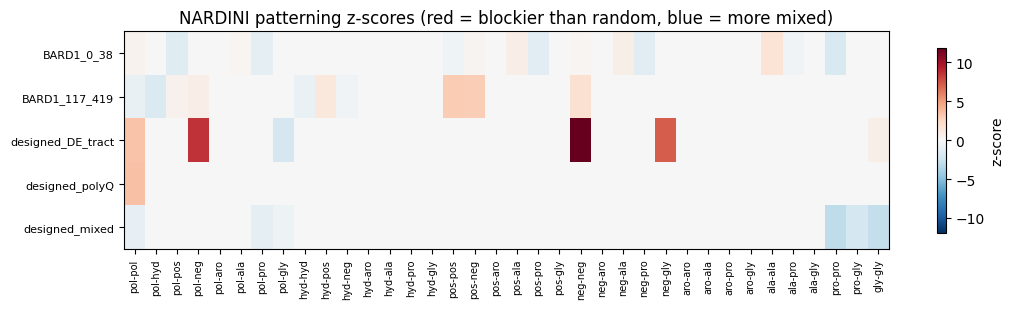

In [16]:
patterning_block = result.patterning_zscores
limit = np.abs(patterning_block).max()

fig, ax = plt.subplots(figsize=(11, 3.2))
image = ax.imshow(patterning_block, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")

ax.set_xticks(range(len(result.patterning_feature_names)))
ax.set_xticklabels(result.patterning_feature_names, rotation=90, fontsize=7)
ax.set_yticks(range(len(result.names)))
ax.set_yticklabels(result.names, fontsize=8)
ax.set_title("NARDINI patterning z-scores (red = blockier than random, blue = more mixed)")
fig.colorbar(image, ax=ax, label="z-score", shrink=0.85)
plt.tight_layout()
plt.show()

## GIN cluster assignment across a set

`result.gin_clusters()` assigns every sequence at once. The result carries the label plus
the diagnostics that tell you whether to believe it.

In [17]:
assignment = result.gin_clusters()

print(f"{'sequence':22s} {'cl':>3s} {'grammar':44s} {'dist':>7s} {'sep':>7s} "
      f"{'sat':>4s} {'rms_z':>6s}  ok")
for record in assignment.records():
    print(
        f"{record['name']:22s} {record['cluster']:3d} {record['description']:44s} "
        f"{record['distance']:7.1f} {record['separation']:7.2f} "
        f"{record['n_saturated']:4d} {record['composition_rms_z']:6.2f}  "
        f"{record['is_typical']}"
    )

sequence                cl grammar                                         dist     sep  sat  rms_z  ok
BARD1_0_38              26 R patches                                       54.6    2.88    1   1.26  True
BARD1_117_419            9 Blocks of positive & negative residues          21.2    9.61    1   0.49  True
designed_DE_tract        7 D/E-tracts                                      66.5   41.13   10   2.76  False
designed_polyQ          11 Q-tracts                                        61.7   33.76    7   3.57  False
designed_mixed          10 Well-mixed hydrophobics, enriched in M          76.7    2.70    3   1.13  True


Two things to read off this table.

First, the labels are **semantically right**: the D/E construct lands in `'D/E-tracts'`,
the poly-Q construct in `'Q-tracts'`. The method works.

Second, those same two rows are flagged `is_typical = False`, with `composition_rms_z`
well above 2. This is not a contradiction — it is the point. The GIN clusters describe the
*human IDRome*, and a designed 53-mer of alternating D and E is nowhere near that
population. The nearest-centroid label tells you which grammar it most resembles; it does
not license the claim that it is a member of that cluster. The real BARD1 IDRs, by
contrast, pass the screen.

In [18]:
print("arrays, if you prefer them to dicts:")
print("  clusters          :", assignment.clusters)
print("  distances         :", np.round(assignment.distances, 1))
print("  separations       :", np.round(assignment.separations, 2))
print("  n_saturated       :", assignment.n_saturated)
print("  composition_rms_z :", np.round(assignment.composition_rms_z, 2))
print("  is_typical        :", assignment.is_typical)
print("  all_distances     :", assignment.all_distances.shape, "(every sequence x all 30 centroids)")

arrays, if you prefer them to dicts:
  clusters          : [26  9  7 11 10]
  distances         : [54.6 21.2 66.5 61.7 76.7]
  separations       : [ 2.88  9.61 41.13 33.76  2.7 ]
  n_saturated       : [ 1  1 10  7  3]
  composition_rms_z : [1.26 0.49 2.76 3.57 1.13]
  is_typical        : [ True  True False False  True]
  all_distances     : (5, 30) (every sequence x all 30 centroids)


`all_distances` is the raw material for anything more sophisticated than a single label —
soft assignments, distance-to-cluster heatmaps, or nearest-neighbour analyses across a
dataset. `ranked_clusters()` is the convenient view of it for one sequence.

In [19]:
for cluster, description, distance in assignment.ranked_clusters("BARD1_117_419", n=4):
    print(f"  {cluster:3d}  {description:46s} d = {distance:7.2f}")

    9  Blocks of positive & negative residues         d =   21.17
   25  Blocks of positive residues                    d =   30.78
   12  Blocks of positive, negative & polar residues  d =   34.50
    4  Weak negative charge, high N fraction          d =   39.92


### The cluster definitions themselves

`gin_cluster_definitions()` returns all 30 published grammars with the number of human IDRs
in each — useful for knowing whether your sequence landed in a large, well-populated
cluster or a small one.

In [20]:
definitions = gin_cluster_definitions()

print(f"{'cl':>3s}  {'grammar':46s} {'human IDRs':>10s}")
for entry in sorted(definitions, key=lambda d: -d["num_idrs"]):
    print(f"{entry['cluster']:3d}  {entry['description']:46s} {entry['num_idrs']:10d}")

print()
print("total human IDRs across all clusters:", sum(d["num_idrs"] for d in definitions))

 cl  grammar                                        human IDRs
  6  S patches                                            1833
 24  Weak negative charge                                 1810
 17  Weak positive charge                                 1739
  4  Weak negative charge, high N fraction                1537
 29  High R fraction                                      1482
 27  P patches                                            1386
 19  High negative fraction, specifically Es              1375
 25  Blocks of positive residues                          1234
  3  Small negative blocks                                1097
 23  K blocks                                             1043
  9  Blocks of positive & negative residues                939
 20  A blocks                                              803
 28  High aromatic fraction, specifically Ys               768
  7  D/E-tracts                                            763
  1  Blocks of P & polar residues                      

One number worth knowing when you interpret `distance`: how far apart the centroids are
from each other. `separation_scale` reports the typical spacing, and it is *much* smaller
than the distances you saw above.

In [21]:
reference = load_gin_reference()

print("typical spacing between centroids   :", round(reference.separation_scale, 2))
for record in assignment.records():
    print(f"  {record['name']:22s} distance to nearest = {record['distance']:6.2f}")
print()
print("centroid coordinate range:", round(reference.centroids.min(), 2),
      "to", round(reference.centroids.max(), 2))

typical spacing between centroids   : 17.81
  BARD1_0_38             distance to nearest =  54.64
  BARD1_117_419          distance to nearest =  21.17
  designed_DE_tract      distance to nearest =  66.53
  designed_polyQ         distance to nearest =  61.72
  designed_mixed         distance to nearest =  76.67

centroid coordinate range: -2.32 to 2.99


This is the curse of dimensionality, and it is why **distance to the nearest centroid is
not a usable absolute measure of typicality**. In 90 dimensions even a perfectly ordinary
z-vector sits several times further from its nearest centroid than the centroids sit from
each other, because centroids are cluster *means* rather than members. Compare distances
between sequences; never against a fixed threshold. Use `composition_rms_z` for "is this
IDR-like?" and `separation` for "is this label unambiguous?".

Note also that the centroids only span roughly -2.3 to +3.0 in each coordinate, which is
why `n_saturated` matters: a feature clipped at ±3 sits outside the range any centroid
describes, and contributes the same amount to every centroid distance, so it cannot
discriminate between them.

## Reading from a FASTA file

Everything above took a dict, but `nardini_vectors()` and `build_background()` both accept
a FASTA path directly, which is the normal case for real data. Extra keyword arguments are
passed through to `protfasta.read_fasta`.

In [22]:
with tempfile.TemporaryDirectory() as directory:
    fasta = Path(directory) / "idrs.fasta"
    with open(fasta, "w") as handle:
        for name, sequence in sequences.items():
            handle.write(f">{name}\n{sequence}\n")

    from_file = nardini_vectors(fasta, background=human, num_scrambles=10000, seed=42)

print("from a FASTA:", from_file)
print("identical to the dict version:",
      np.allclose(from_file.zscores, result.zscores))

from a FASTA: NardiniResult|5 sequences|90 features
identical to the dict version: True


The per-sequence seed is derived from `seed` **and the sequence itself**, not from its
position in the batch. That is what makes the comparison above hold exactly, and it means
you can re-score one sequence out of a set, or score the set in a different order, and get
identical numbers.

In [23]:
subset = nardini_vectors(
    {"designed_polyQ": sequences["designed_polyQ"]},
    background=human, num_scrambles=10000, seed=42,
)

index = result.names.index("designed_polyQ")
print(f"designed_polyQ sits at index {index} in the batch of {len(result)}")
print("scored alone vs in the batch    :",
      np.allclose(subset.zscores[0], result.zscores[index]))

# and reordering the batch changes nothing either
shuffled = nardini_vectors(
    dict(reversed(list(sequences.items()))),
    background=human, num_scrambles=10000, seed=42,
)
print("batch reversed                 :",
      np.allclose(shuffled.zscores[shuffled.names.index("designed_polyQ")],
                  result.zscores[index]))

# Protein.nardini agrees with the batch too, since it is the same code underneath
solo = Protein(sequences["designed_polyQ"]).nardini.vector(
    background=human, num_scrambles=10000, seed=42
)
print("via Protein.nardini            :",
      np.allclose(solo.to_numpy(), result.zscores[index]))

designed_polyQ sits at index 3 in the batch of 5
scored alone vs in the batch    : True


batch reversed                 : True
via Protein.nardini            : True


For large sets, `show_progress=True` gives a progress bar. Cost is linear in
`num_scrambles` and roughly linear in the number of sequences; the published protocol uses
100,000 scrambles, the default here is 10,000, and 1,000 is usually plenty for
low-complexity sequences. If a z-score matters to your conclusion, check that it is stable
as you increase the count.

## Patterning only, no background

Pass `background=None` to skip the compositional half entirely. You get the 36 patterning
features, which need no reference set and are meaningful for any sequence — including ones
nowhere near a human IDR.

In [24]:
patterning_only = nardini_vectors(sequences, num_scrambles=2000, seed=42)

print(patterning_only)
print("has_composition:", patterning_only.has_composition)
print("shape          :", patterning_only.zscores.shape)

NardiniResult|5 sequences|36 features
has_composition: False
shape          : (5, 36)


## A whole proteome, in parallel

Everything so far ran in one process. The scramble-based patterning null is the
expensive part, and it is embarrassingly parallel, so
`nardini_proteins()` spreads it across cores and hands back `Protein` objects with
the vectors **already attached** — so the cost is paid once, up front, and every
later call is free.

In [25]:
import time

from sparrow.nardini import nardini_proteins

# a realistic-ish set: 60 of the synthetic IDRs from earlier
subset = {name: my_idrs[name] for name in list(my_idrs)[:60]}
options = dict(background=human, num_scrambles=1000, seed=42)

t = time.perf_counter()
serial = nardini_proteins(subset, n_processes=1, **options)
serial_time = time.perf_counter() - t

t = time.perf_counter()
parallel = nardini_proteins(subset, n_processes=4, **options)
parallel_time = time.perf_counter() - t

print(f"1 process  : {serial_time:5.2f} s")
print(f"4 processes: {parallel_time:5.2f} s   ({serial_time / parallel_time:.1f}x)")

1 process  :  7.31 s
4 processes:  2.09 s   (3.5x)


The results are `Protein` objects, and the vectors are cached on them:

In [26]:
first = list(subset)[0]
protein = parallel[first]
print(first, "->", type(protein).__name__, "of length", len(protein))

# free - served from the cache the batch run populated
vector = protein.nardini.vector(**options)
print("vector:", vector)
print("  Frac K+R =", round(vector["Frac K+R"], 3))
print("  GIN     :", protein.nardini.gin_cluster(**options)["description"])

idr_000 -> Protein of length 325
vector: FeatureVector 'sequence'|90 features
  Frac K+R = -0.089
  GIN     : Weak negative charge


**Parallelism does not change the numbers.** Per-sequence seeds are derived from the
sequence itself rather than its position in the batch, so a vector does not depend
on how the input was chunked or how many processes ran:

In [27]:
same = all(
    np.allclose(
        serial[name].nardini.vector(**options).to_numpy(),
        parallel[name].nardini.vector(**options).to_numpy(),
    )
    for name in subset
)
print("1 process vs 4 processes, identical for all 60 sequences:", same)

1 process vs 4 processes, identical for all 60 sequences: True


### Input shapes

It takes sequences or `Protein` objects, as a dict or a list, and gives back the
same shape. `Protein` objects you pass in are populated **in place**, so references
you already hold are updated too.

In [28]:
from sparrow import Protein

three = list(subset.values())[:3]

as_dict = nardini_proteins(dict(zip("abc", three)), num_scrambles=200, seed=1)
as_list = nardini_proteins(three, num_scrambles=200, seed=1)

mine = [Protein(s) for s in three]
returned = nardini_proteins(mine, num_scrambles=200, seed=1)

print("dict in  ->", type(as_dict).__name__, sorted(as_dict))
print("list in  ->", type(as_list).__name__, len(as_list))
print("Protein objects populated in place:", returned[0] is mine[0])

dict in  -> dict ['a', 'b', 'c']
list in  -> list 3
Protein objects populated in place: True


Two practical notes for real proteomes:

- **`on_error='skip'`** drops entries NARDINI cannot score — a non-standard residue,
  or something shorter than the window — and warns with a summary. The default
  raises, which is a poor outcome several hours into a run.
- **On Windows**, or if you pass `start_method='spawn'`, call it from inside an
  `if __name__ == "__main__":` block. sparrow defaults to `fork` where it exists,
  which needs no guard and works inside notebooks like this one.

## Deriving your own grammars

Assigning to the 30 published human clusters only makes sense if your sequences
resemble human IDRs. For anything else — a non-human proteome, a designed library —
you can run the same clustering procedure on your own vectors and get a reference
that `assign_gin_clusters()` accepts in place of the published one.

Clustering only finds structure that is actually there. The synthetic set above is
compositionally uniform, so its clusters come out indistinct. To see the machinery
work, here is a set with four grammars planted deliberately — D/E tracts, poly-Q,
S-rich, and K blocks — which the clustering should recover without being told.

In [29]:
from sparrow.nardini import (
    assign_gin_clusters,
    build_gin_reference,
    compare_gin_references,
)

grammar_rng = random.Random(3)
planted = {}
for index in range(10):
    planted[f"DE_{index}"] = "GS" + "DE" * grammar_rng.randint(30, 45)
    planted[f"polyQ_{index}"] = "GS" + "Q" * grammar_rng.randint(50, 80) + "PSPS" * 4
    planted[f"Srich_{index}"] = "".join(
        grammar_rng.choice("SSSSTGSP") for _ in range(grammar_rng.randint(120, 180))
    )
    planted[f"Kblock_{index}"] = "GS" + ("K" * 12 + "GSGS") * grammar_rng.randint(4, 7)

own_vectors = nardini_vectors(planted, background=human, num_scrambles=1000, seed=42)

reference = build_gin_reference(own_vectors, k=4, seed=0)
print(reference, "| backend:", reference.backend)
print()
for cluster in range(len(reference)):
    print(f"  cluster {cluster} (n={reference.num_idrs[cluster]:2d}): {reference.describe(cluster)}")

GINReference|4 clusters|90 features | backend: nardini

  cluster 0 (n=10): low Frac Aliphatic, high Frac E, high Frac D
  cluster 1 (n=10): blocky pol-pol, high Frac Q, low Frac Aliphatic
  cluster 2 (n=10): high Frac K, high Frac K+R, low Frac Aliphatic
  cluster 3 (n=10): S patches, high Frac Polar, high Disorder Promoting


Each planted grammar became its own cluster, and the generated descriptions name it
correctly. We can check the recovery explicitly:

In [30]:
assignment = assign_gin_clusters(own_vectors, reference=reference)

for label in ("DE", "polyQ", "Srich", "Kblock"):
    members = [
        int(cluster)
        for name, cluster in zip(own_vectors.names, assignment.clusters)
        if name.startswith(label)
    ]
    counts = np.bincount(members, minlength=4)
    print(f"  {label:7s} -> cluster {int(np.argmax(counts))}  ({counts.max()}/10 together)")

  DE      -> cluster 0  (10/10 together)
  polyQ   -> cluster 1  (10/10 together)
  Srich   -> cluster 3  (10/10 together)
  Kblock  -> cluster 2  (10/10 together)


Those descriptions are generated from each centroid's most extreme features — they
are not the published human-authored labels, which clustering cannot regenerate.
Cluster *numbers* are ordered by size, and mean nothing across runs.

Save it: the vectors behind a real proteome cost hours, and re-clustering with a
different seed gives different (equally valid) centroids.

In [31]:
import tempfile
from pathlib import Path

from sparrow.nardini.gin import GINReference

with tempfile.TemporaryDirectory() as directory:
    path = reference.save(Path(directory) / "my_grammars.npz")
    reloaded = GINReference.load(path)

print("round-tripped:", reloaded)
print("assigning against it:", assign_gin_clusters(own_vectors, reference=reloaded))

round-tripped: GINReference|4 clusters|90 features
assigning against it: GINAssignment|40 sequences


### Did this recover GIN?

Cluster numbering is arbitrary, so comparing labels is meaningless.
`compare_gin_references()` pairs centroids one-to-one against another reference
(the published human one by default) and reports the distances.

In [32]:
report = compare_gin_references(reference)

print(f"mean match distance        : {report['mean_distance']:7.2f}   (squared Euclidean)")
print(f"published centroid spacing : {report['separation_scale']:7.2f}")
print(f"MY centroid spacing        : {report['reference_separation_scale']:7.2f}")
print()
for pair in report["pairs"]:
    print(f"  my {pair['cluster']} ({pair['description'][:34]:36s}) -> "
          f"published {pair['matched_cluster']:2d} {pair['matched_description'][:26]:28s} d={pair['distance']:6.1f}")

mean match distance        :   76.84   (squared Euclidean)
published centroid spacing :   17.81
MY centroid spacing        :  165.36

  my 0 (low Frac Aliphatic, high Frac E, h  ) -> published  7 D/E-tracts                   d=  95.6
  my 1 (blocky pol-pol, high Frac Q, low F  ) -> published 11 Q-tracts                     d=  65.7
  my 2 (high Frac K, high Frac K+R, low Fr  ) -> published 23 K blocks                     d=  87.7
  my 3 (S patches, high Frac Polar, high D  ) -> published 15 T patches                    d=  58.4


Notice what the pairing found: our D/E cluster matched the published
`'D/E-tracts'`, poly-Q matched `'Q-tracts'`, and the K-block cluster matched
`'K blocks'`. Nothing told it to — the matching is purely geometric, on centroid
distances. That is a good sign the machinery is doing what it claims.

But read the three numbers together, because they say something different. The mean
match distance (~77) is far *above* the published centroid spacing (~18), so these
are not the same clusters in the same places. Our own spacing (~165) is also much
larger than the published one — these designed sequences are compositionally
extreme, so their centroids sit far apart and far from anything in the human
IDRome. The grammars are recognisably analogous; the coordinates are not the same.

The failure mode to watch for is the opposite one. A clustering that found no real
structure leaves all its centroids near the origin, which makes them close to
everything and produces a flatteringly *small* match distance. If your own spacing
sits far below the published one, your clusters are not comparable structure however
well they appear to match.

Reproducing the published 30 centroids exactly is not realistic: sparrow ships the
centroids but not the IDRome sequences, "the human IDRome" is itself a definition,
k-means depends on its initialization, and some hyperparameters were never
documented upstream. Building your own clusters and *measuring* the distance to the
published ones is the achievable goal.

## Citation

sparrow is an independent implementation, not the source of the method or the reference
data. Please cite the original work:

- **NARDINI**: Cohan, M. C., Shinn, M. K., Lalmansingh, J. M. & Pappu, R. V. Uncovering
  non-random binary patterns within sequences of intrinsically disordered proteins.
  *J. Mol. Biol.* (2022).
- **GIN / NARDINI+**: Ruff, K. M., King, M. R., Ying, A. W., Liu, V., Pant, A.,
  Lieberman, W. E., Shinn, M. K., Su, X., Kadoch, C. & Pappu, R. V. Molecular grammars of
  predicted intrinsically disordered regions that span the human proteome. *Cell* (2025).

The bundled per-species backgrounds and GIN centroids are redistributed from the
[GIN resource](https://github.com/kierstenruff/RUFF_KING_Grammars_of_IDRs_using_NARDINI-)
under the MIT licence. `sparrow/data/nardini/SOURCES.md` records the provenance of every
bundled file.

See also the
[NARDINI guide](https://idptools-sparrow.readthedocs.io/en/latest/api_guides/nardini.html)
for the full option reference.